# Recipe: Sublimation of ice

Ice-silicate grains (50 % crystalline ice by volume) that become porous silicate where they are warmer than 110 K. The sublimation radius depends on the grain size: small grains are hotter.

**Files:** `examples/sublimation_ice.nml`  
**Run time:** about 15 s  
**Manual:** Sect. 16.10 of `docs/manual/dms_manual.pdf`. The same code as a script: `python3 examples/recipes/sublimation.py`.

In [1]:
# Setup: this notebook lives in examples/recipes/ of the repository
import os, sys
if "REPO" not in globals():
    REPO = os.environ.get("DMS_REPO") or os.path.abspath(os.path.join("..", ".."))
sys.path.insert(0, os.path.join(REPO, "python"))      # use the DMS of this repository
os.chdir(REPO)                                        # input files and cache/ are relative to the root
import dms
import numpy as np
import matplotlib.pyplot as plt
print("DMS", dms.__version__)

DMS 2.2.1


a =    1.04 micron: ice sublimates inside  51.6 au
a =    4.12 micron: ice sublimates inside  28.0 au
a =   16.41 micron: ice sublimates inside  21.1 au
a =   65.31 micron: ice sublimates inside  23.8 au
a =  260.02 micron: ice sublimates inside  26.0 au


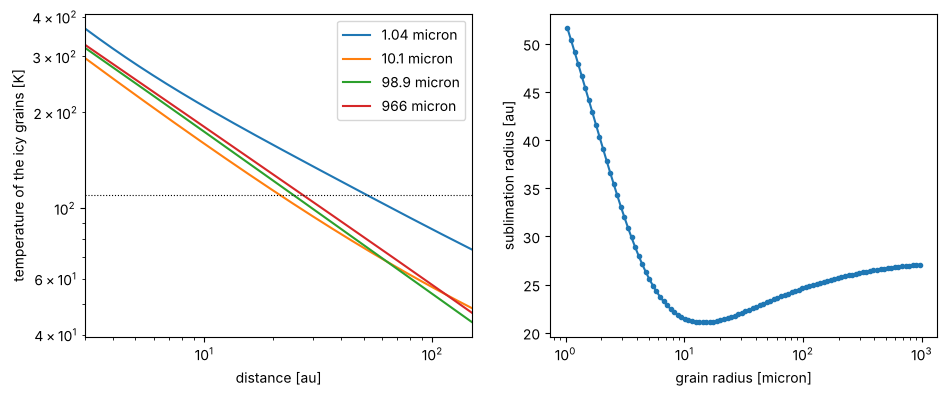

In [2]:
res = dms.Model.from_file("examples/sublimation_ice.nml").run()
T = res.temperature                                   # T["T"][distance, component, size]
a = res.grains["a"]
r_subl = np.array([T["r_au"][T["T"][:, 0, i] >= 110.0].max() if (T["T"][:, 0, i] >= 110.0).any() else np.nan
                   for i in range(len(a))])
for i in range(0, len(a), 20):
    print(f"a = {a[i]:7.2f} micron: ice sublimates inside {r_subl[i]:5.1f} au")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for i in (0, len(a) // 3, 2 * len(a) // 3, len(a) - 1):
    ax[0].loglog(T["r_au"], T["T"][:, 0, i], label=f"{a[i]:.3g} micron")
ax[0].axhline(110, color="k", lw=0.8, ls=":")
ax[0].set_xlim(3, 150); ax[0].set_xlabel("distance [au]"); ax[0].set_ylabel("temperature of the icy grains [K]")
ax[0].legend()
ax[1].semilogx(a, r_subl, marker=".")
ax[1].set_xlabel("grain radius [micron]"); ax[1].set_ylabel("sublimation radius [au]")
plt.show()

**Result.** The ice sublimates inside 52 au for 1 µm grains, which are the hottest; the sublimation radius has a minimum of 21 au near 15 µm and is 26 au for the largest grains.